# Exploratory Data Analysis: campaign-day performance

This notebook explores the campaign-day dataset used to predict whether a campaign's **next-day CTR beats its benchmark**.
It covers data quality, the distribution of CTR across platforms and objectives, and the patterns the features are designed
to capture (persistence, creative fatigue, day-of-week effects, spend scaling).

> **Data source.** The pipeline loads `data/raw/campaign_daily.csv`. Re-run this notebook after changing the input data.


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from src import config, data, features
from src.plotting import PLATFORM_COLORS, SERIES, AXIS, NEGATIVE, NEUTRAL, POSITIVE, INK_SECONDARY, SURFACE, apply_style, save

apply_style()
%matplotlib inline
FIG = config.FIGURES_DIR
pd.set_option("display.precision", 3)

## 1. Load and clean

In [2]:
raw_path = config.DATA_PATH
raw = pd.read_csv(raw_path)
print(f"Source: {raw_path.name}")
print(f"Raw rows: {len(raw):,}   columns: {list(raw.columns)}")
raw.head()

Source: campaign_daily.csv
Raw rows: 4,933   columns: ['date', 'campaign_id', 'platform', 'objective', 'spend', 'impressions', 'clicks']


,date,campaign_id,platform,objective,spend,impressions,clicks
0,2025-01-21,cmp_080,Google Ads,Leads,74.41,1891,93
1,2025-04-07,cmp_021,Google Ads,Leads,64.23,1192,51
2,2025-05-07,cmp_081,Google Ads,Sales,76.00,2042,69
3,2025-04-04,cmp_078,Meta Ads,Awareness,42.08,8003,41
4,2025-05-04,cmp_002,Meta Ads,Traffic,185.09,18893,270


In [3]:
print("Missing values per column:")
print(raw.isna().sum())
print("\nNegative values:", int((raw[['spend', 'impressions', 'clicks']] < 0).sum().sum()))
print("Clicks > impressions:", int((raw['clicks'] > raw['impressions']).sum()))
print("Duplicate campaign-days:", int(raw.duplicated(['campaign_id', 'date']).sum()))

Missing values per column:
date           0
campaign_id    0
platform       0
objective      0
spend          0
impressions    0
clicks         0
dtype: int64

Negative values: 0
Clicks > impressions: 0
Duplicate campaign-days: 25


In [4]:
panel = data.clean(raw)
panel.describe(include="all").T

Cleaning summary: {'rows_in': 4933, 'no_date': 0, 'invalid_values': 0, 'duplicates_merged': 25, 'gap_days_filled': 104, 'rows_out': 5012, 'campaigns': 90}


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,5012,NaN,NaN,NaN,2025-06-11 16:36:23.559457,2025-01-11 00:00:00,2025-04-01 00:00:00,2025-05-30 00:00:00,2025-08-31 00:00:00,2025-10-30 00:00:00,NaN
campaign_id,5012,90,cmp_040,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
platform,5012,2,Meta Ads,2627,NaN,NaN,NaN,NaN,NaN,NaN,NaN
objective,5012,5,Leads,1410,NaN,NaN,NaN,NaN,NaN,NaN,NaN
spend,5012.0,NaN,NaN,NaN,126.605,0.0,45.593,73.6,152.572,1743.34,157.504
impressions,5012.0,NaN,NaN,NaN,9943.368,0.0,2719.0,5570.0,10559.75,118122.0,13129.777
clicks,5012.0,NaN,NaN,NaN,111.907,0.0,39.0,68.0,139.0,1549.0,124.727


Cleaning steps (see `src/data.py`): parse dates and numbers, drop export summary rows, drop impossible values
(negative counts, clicks > impressions), merge duplicate campaign-days, and fill calendar gaps inside each campaign
with zero-delivery days so rolling windows are measured in calendar days.

## 2. Campaign mix

In [5]:
daily_ctr = panel.assign(ctr=100 * panel["clicks"] / panel["impressions"].where(panel["impressions"] > 0))
mix = (daily_ctr.groupby(["platform", "objective"])
       .agg(campaigns=("campaign_id", "nunique"), campaign_days=("date", "size"),
            avg_daily_spend=("spend", "mean"), avg_daily_impressions=("impressions", "mean"),
            median_daily_ctr_pct=("ctr", "median")))
mix

campaigns  campaign_days  avg_daily_spend  \
platform   objective                                               
Google Ads Awareness           7            376          121.862   
           Engagement          3            152           44.305   
           Leads              15            878          133.082   
           Sales              11            554          195.107   
           Traffic             8            425          128.022   
Meta Ads   Awareness          10            556           76.810   
           Engagement          6            270          127.615   
           Leads              10            532           97.258   
           Sales              13            776          154.889   
           Traffic             7            493          108.616   

                       avg_daily_impressions  median_daily_ctr_pct  
platform   objective                                                
Google Ads Awareness               36924.316                 0.534  
           Engagement               5714.125                 1.649  
           Leads                    2796.208                 4.597  
           Sales                    4598.572                 3.389  
           Traffic                  4222.513                 3.251  
Meta Ads   Awareness               14730.362                 0.451  
           Engagement              15737.111                 0.862  
           Leads                    6906.483                 0.747  
           Sales                    8935.633                 0.777  
           Traffic                 10627.627                 1.148

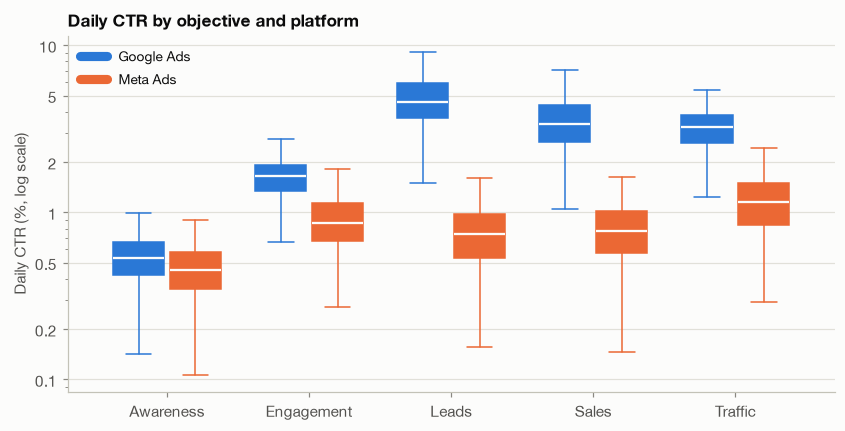

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.2))
objectives = sorted(daily_ctr["objective"].unique())
platforms = sorted(daily_ctr["platform"].unique())
width = 0.36
for i, platform in enumerate(platforms):
    vals = [daily_ctr.loc[(daily_ctr.platform == platform) & (daily_ctr.objective == o) & (daily_ctr.impressions >= config.MIN_IMPRESSIONS), "ctr"].dropna()
            for o in objectives]
    pos = np.arange(len(objectives)) + (i - 0.5) * (width + 0.04)
    bp = ax.boxplot(vals, positions=pos, widths=width, patch_artist=True, showfliers=False,
                    medianprops=dict(color=SURFACE, lw=1.5), whiskerprops=dict(color=PLATFORM_COLORS[platform]),
                    capprops=dict(color=PLATFORM_COLORS[platform]))
    for b in bp["boxes"]:
        b.set(facecolor=PLATFORM_COLORS[platform], edgecolor=PLATFORM_COLORS[platform])
    ax.plot([], [], color=PLATFORM_COLORS[platform], lw=6, label=platform)
ax.set_xticks(range(len(objectives)), objectives)
ax.set_yscale("log")
ax.set_yticks([0.1, 0.2, 0.5, 1, 2, 5, 10], ["0.1", "0.2", "0.5", "1", "2", "5", "10"])
ax.set(ylabel="Daily CTR (%, log scale)", title="Daily CTR by objective and platform")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
fig.savefig(FIG / "eda_ctr_by_group.png"); plt.show()

**What to look for:** CTR levels differ systematically by objective and platform. This is why the benchmark is defined per
*platform × objective* (comparing like with like); a single global benchmark would mostly measure campaign type.

## 3. Modelling dataset and target

In [7]:
feats, meta = features.prepare_dataset(panel)
print(f"Modelling rows: {len(feats):,}")
print("Benchmarks (median daily CTR %, training period only):")
for k, v in meta["benchmark_ctr_pct"].items():
    print(f"  {k:28s} {v:.3f}%")
feats.groupby("split").agg(rows=(config.TARGET, "size"), share_above=(config.TARGET, "mean"),
                           first=("target_date", "min"), last=("target_date", "max")).loc[["train", "val", "test"]]

Modelling rows: 4,818
Benchmarks (median daily CTR %, training period only):
  Google Ads | Awareness       0.536%
  Google Ads | Engagement      1.698%
  Google Ads | Leads           4.408%
  Google Ads | Sales           3.369%
  Google Ads | Traffic         3.187%
  Meta Ads | Awareness         0.455%
  Meta Ads | Engagement        0.843%
  Meta Ads | Leads             0.776%
  Meta Ads | Sales             0.737%
  Meta Ads | Traffic           1.172%


,rows,share_above,first,last
split,,,,
train,3383,0.502,2025-01-13,2025-08-17
val,716,0.542,2025-08-18,2025-09-24
test,719,0.552,2025-09-25,2025-10-30


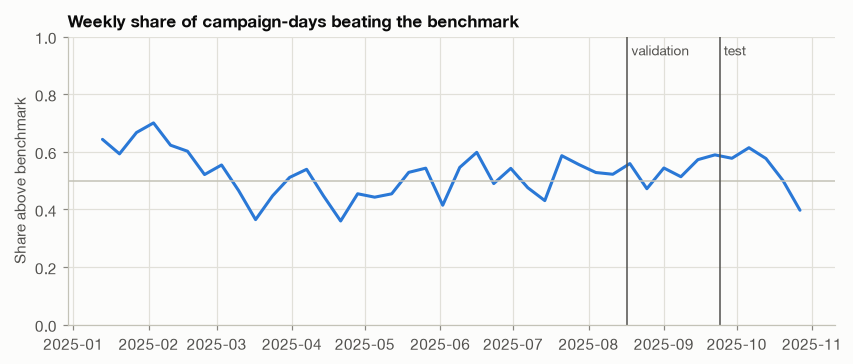

In [8]:
weekly = (feats.assign(week=feats["target_date"].dt.to_period("W").dt.start_time)
               .groupby("week")[config.TARGET].agg(["mean", "size"]))
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(weekly.index, weekly["mean"], color=SERIES[0])
ax.axhline(0.5, color=AXIS, lw=1)
for label, d in [("validation", meta["train_end"]), ("test", meta["val_end"])]:
    ax.axvline(pd.Timestamp(d), color=INK_SECONDARY, lw=1)
    ax.text(pd.Timestamp(d), 0.98, f" {label}", va="top", fontsize=9, color=INK_SECONDARY, transform=ax.get_xaxis_transform())
ax.set(ylim=(0, 1), ylabel="Share above benchmark", title="Weekly share of campaign-days beating the benchmark")
fig.savefig(FIG / "eda_target_over_time.png"); plt.show()

**What to look for:** class balance near 50% in training (by construction of a median benchmark) and any drift
in the validation/test periods; drift is one reason the split is chronological rather than random.

## 4. Patterns behind the features

### 4.1 Persistence: does today's CTR predict tomorrow's?

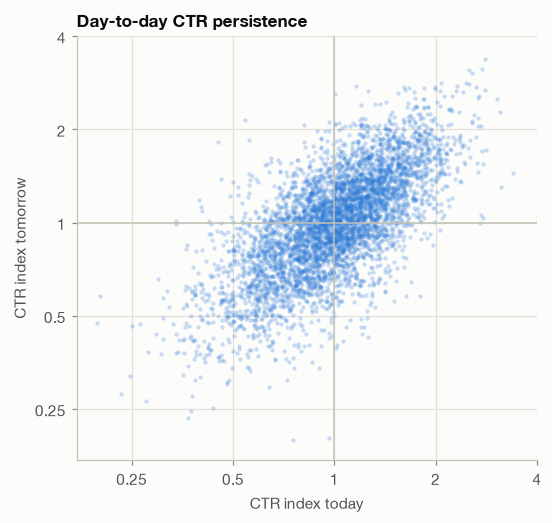

Spearman correlation, today vs tomorrow index: 0.673
Spearman correlation, 7-day vs tomorrow index: 0.664


In [9]:
lab = feats.assign(next_index=feats["next_ctr"] / feats["benchmark_ctr"])
fig, ax = plt.subplots(figsize=(5.4, 5))
ax.scatter(lab["ctr_index_1d"], lab["next_index"], s=8, alpha=0.25, color=SERIES[0], linewidths=0)
ax.axhline(1, color=AXIS, lw=1); ax.axvline(1, color=AXIS, lw=1)
ax.set(xscale="log", yscale="log", xlabel="CTR index today", ylabel="CTR index tomorrow",
       title="Day-to-day CTR persistence")
ticks = [0.25, 0.5, 1, 2, 4]
ax.set_xticks(ticks, [f"{t:g}" for t in ticks]); ax.set_yticks(ticks, [f"{t:g}" for t in ticks])
ax.minorticks_off()
fig.savefig(FIG / "eda_persistence.png"); plt.show()
print("Spearman correlation, today vs tomorrow index:",
      round(lab[["ctr_index_1d", "next_index"]].corr(method="spearman").iloc[0, 1], 3))
print("Spearman correlation, 7-day vs tomorrow index:",
      round(lab[["ctr_index_7d", "next_index"]].corr(method="spearman").iloc[0, 1], 3))

A strong but imperfect correlation means a naive *persistence* rule ("tomorrow = today") is a meaningful baseline,
which the models are compared against in `src/train.py`.

### 4.2 Creative fatigue: CTR versus campaign age

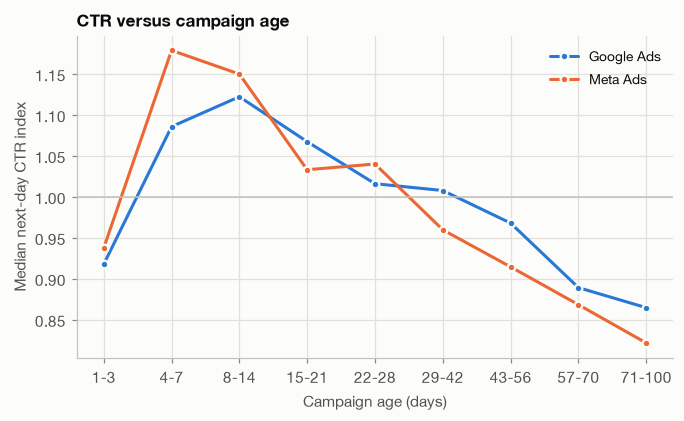

In [10]:
age_bins = [0, 3, 7, 14, 21, 28, 42, 56, 70, 100]
fat = (lab.assign(age=pd.cut(lab["campaign_day"], age_bins))
          .groupby(["platform", "age"], observed=True)["next_index"].median().unstack(0))
fig, ax = plt.subplots(figsize=(7, 3.8))
for platform in fat.columns:
    ax.plot(range(len(fat)), fat[platform], color=PLATFORM_COLORS[platform], marker="o", ms=5,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=platform)
ax.axhline(1, color=AXIS, lw=1)
ax.set_xticks(range(len(fat)), [f"{int(i.left)+1}-{int(i.right)}" for i in fat.index])
ax.set(xlabel="Campaign age (days)", ylabel="Median next-day CTR index", title="CTR versus campaign age")
ax.legend()
fig.savefig(FIG / "eda_fatigue.png"); plt.show()

### 4.3 Day-of-week effects

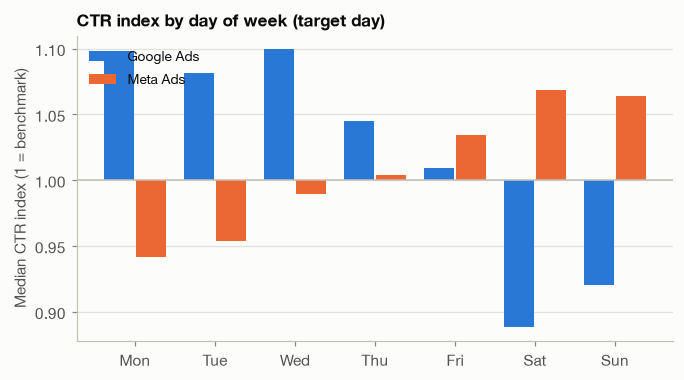

In [11]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow = lab.groupby(["day_of_week", "platform"])["next_index"].median().unstack().reindex(days)
fig, ax = plt.subplots(figsize=(7, 3.6))
w = 0.38
for i, platform in enumerate(dow.columns):
    # Bars grow from the benchmark line (index 1.0), so their length is the deviation from benchmark.
    ax.bar(np.arange(7) + (i - 0.5) * (w + 0.02), dow[platform] - 1, bottom=1, width=w,
           color=PLATFORM_COLORS[platform], label=platform)
ax.axhline(1, color=AXIS, lw=1)
ax.set_xticks(range(7), days)
ax.set(ylabel="Median CTR index (1 = benchmark)", title="CTR index by day of week (target day)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
fig.savefig(FIG / "eda_day_of_week.png"); plt.show()

### 4.4 Spend scaling: does spending above the usual level change CTR?

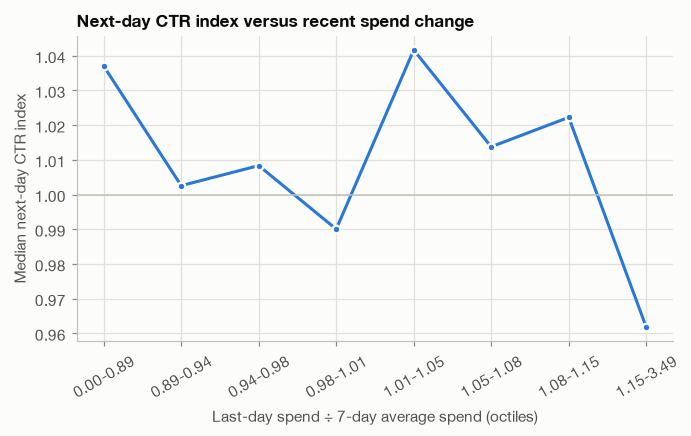

In [12]:
ratio = lab["spend_1d"] / lab["spend_7d_avg"].where(lab["spend_7d_avg"] > 0)
sc = (lab.assign(ratio_bin=pd.qcut(ratio, 8, duplicates="drop"))
         .groupby("ratio_bin", observed=True).agg(ratio=("spend_1d", "size"), idx=("next_index", "median")))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(range(len(sc)), sc["idx"], color=SERIES[0], marker="o", ms=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.axhline(1, color=AXIS, lw=1)
ax.set_xticks(range(len(sc)), [f"{max(i.left, 0):.2f}-{i.right:.2f}" for i in sc.index], rotation=30)
ax.set(xlabel="Last-day spend ÷ 7-day average spend (octiles)", ylabel="Median next-day CTR index",
       title="Next-day CTR index versus recent spend change")
fig.savefig(FIG / "eda_spend_scaling.png"); plt.show()

## 5. Feature correlations

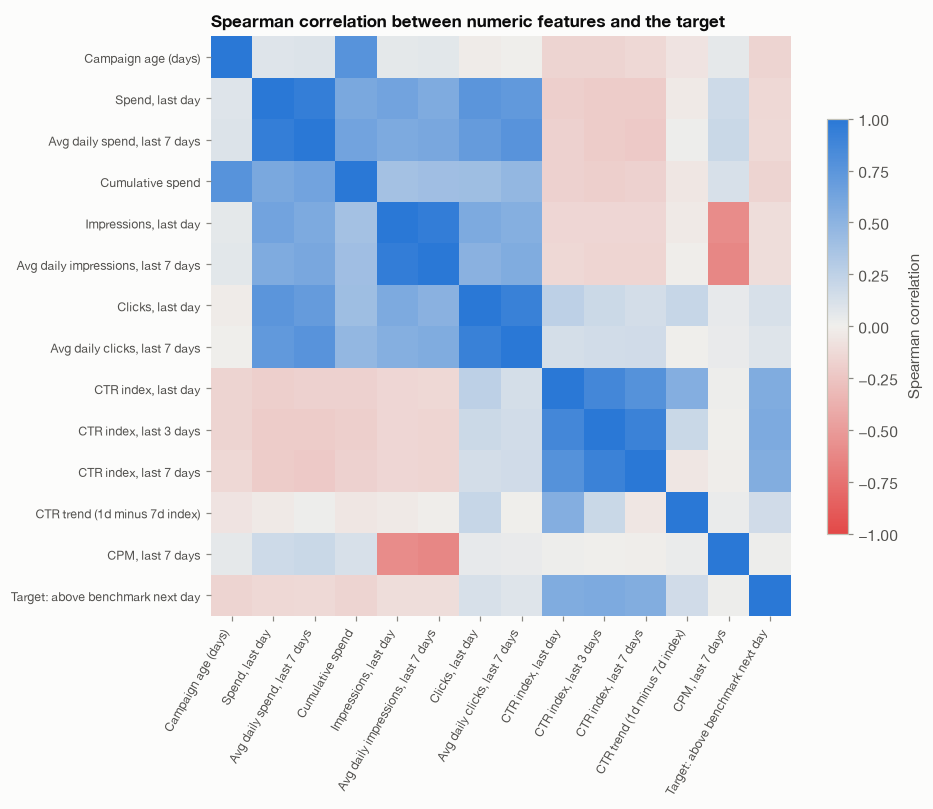

,corr_with_target
ctr_index_3d,0.572
ctr_index_1d,0.557
ctr_index_7d,0.552
ctr_trend,0.163
campaign_day,-0.160
spend_cum,-0.158
spend_1d,-0.137
spend_7d_avg,-0.129
clicks_1d,0.121
impressions_7d_avg,-0.104


In [13]:
corr = feats[config.NUMERIC_FEATURES + [config.TARGET]].corr(method="spearman")
cmap = LinearSegmentedColormap.from_list("div", [NEGATIVE, NEUTRAL, POSITIVE])
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
labels = [config.FEATURE_LABELS.get(c, "Target: above benchmark next day") for c in corr.columns]
ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title("Spearman correlation between numeric features and the target")
fig.savefig(FIG / "eda_correlations.png"); plt.show()
corr[config.TARGET].drop(config.TARGET).sort_values(key=np.abs, ascending=False).to_frame("corr_with_target")

**What to look for:** volume features (spend, impressions, clicks) are strongly inter-correlated, as are the three
CTR-index windows. Collinearity makes linear-model coefficients unstable, but EBM's per-feature shape functions and
pairwise terms remain readable; permutation importance in `src/explain.py` shows how each model distributes credit
across correlated features.

## 6. Summary statistics for the report

In [14]:
summary = {
    "source": raw_path.name,
    "raw_rows": len(raw),
    "cleaning": panel.attrs["cleaning_log"],
    "modelling_rows": len(feats),
    "campaigns": feats["campaign_id"].nunique(),
    "date_range": meta["date_range"],
    "split_rows": feats["split"].value_counts().to_dict(),
    "share_above_benchmark": feats.groupby("split")[config.TARGET].mean().round(3).to_dict(),
}
summary

{'source': 'campaign_daily.csv',
 'raw_rows': 4933,
 'cleaning': {'rows_in': 4933,
  'no_date': 0,
  'invalid_values': 0,
  'duplicates_merged': 25,
  'gap_days_filled': 104,
  'rows_out': 5012,
  'campaigns': 90},
 'modelling_rows': 4818,
 'campaigns': 90,
 'date_range': ['2025-01-11', '2025-10-30'],
 'split_rows': {'train': 3383, 'test': 719, 'val': 716},
 'share_above_benchmark': {'test': 0.552, 'train': 0.502, 'val': 0.542}}